# DS-A2 | Inference and Uncertainty Notebook

Question: Does group A have a higher average score than group B?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(20261012)
df=pd.read_csv('data/ds_a2_sample_data.csv')
df.head()


,group,score
0,A,72
1,A,75
2,A,78
3,A,80
4,A,82


In [2]:
A=df[df.group=='A'].score
B=df[df.group=='B'].score
obs=A.mean()-B.mean()
print(A.mean(),B.mean(),obs)


83.4 76.9 6.5


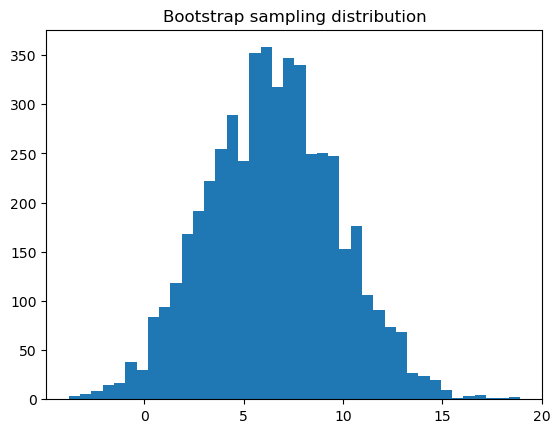

95% CI: 0.20000000000000284 12.900000000000006


In [3]:
sim=[]
for i in range(5000):
    sim.append(A.sample(len(A),replace=True).mean()-B.sample(len(B),replace=True).mean())
plt.hist(sim,bins=40)
plt.title('Bootstrap sampling distribution')
plt.show()
print('95% CI:',np.percentile(sim,2.5),np.percentile(sim,97.5))


In [4]:
pooled=np.sqrt(((len(A)-1)*A.std()**2+(len(B)-1)*B.std()**2)/(len(A)+len(B)-2))
print('Cohen d:',obs/pooled)


Cohen d: 0.8587309193316346


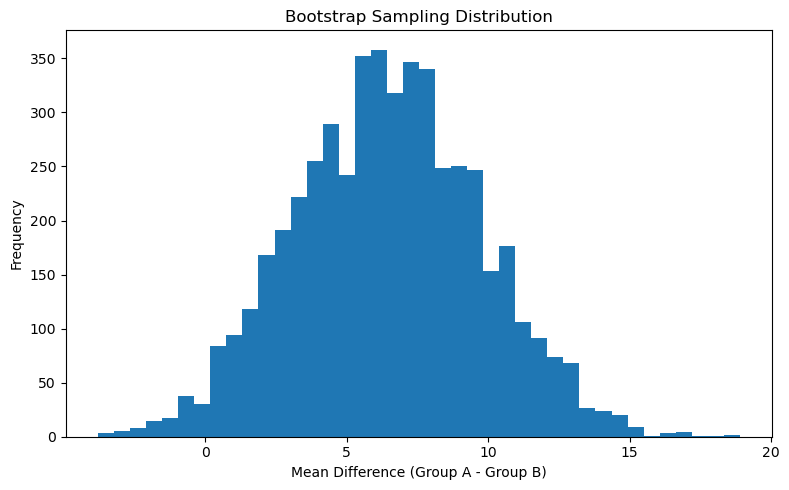

                Metric    Value
0         Group A Mean  83.4000
1         Group B Mean  76.9000
2  Observed Difference   6.5000
3         95% CI Lower   0.2000
4         95% CI Upper  12.9000
5            Cohen's d   0.8587


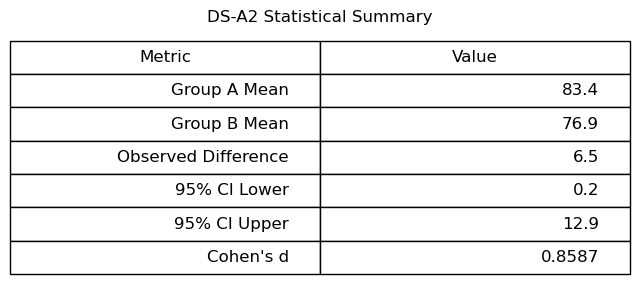

  Confidence Level  Lower Bound  Upper Bound
0              95%          0.2         12.9


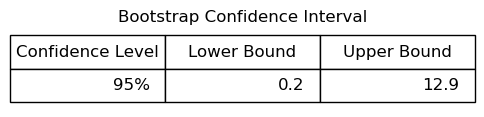

  Effect Measure   Value
0      Cohen's d  0.8587


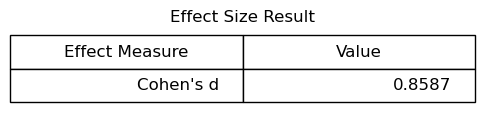

DS-A2 Export Completed Successfully
All files saved in: Results


In [5]:
# ============================================================
# DS-A2 Result Export Cell
# Generate figures and tables for final report
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# Create Results folder
result_dir = "Results"
os.makedirs(result_dir, exist_ok=True)


# ------------------------------------------------------------
# 1. Save Bootstrap Distribution Figure
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.hist(sim, bins=40)

plt.title("Bootstrap Sampling Distribution")
plt.xlabel("Mean Difference (Group A - Group B)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    os.path.join(result_dir,
                 "bootstrap_sampling_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# ------------------------------------------------------------
# 2. Statistical Summary Table
# ------------------------------------------------------------

ci_low = np.percentile(sim, 2.5)
ci_high = np.percentile(sim, 97.5)

cohens_d = obs / pooled


summary_table = pd.DataFrame({

    "Metric":[
        "Group A Mean",
        "Group B Mean",
        "Observed Difference",
        "95% CI Lower",
        "95% CI Upper",
        "Cohen's d"
    ],

    "Value":[
        round(A.mean(),3),
        round(B.mean(),3),
        round(obs,3),
        round(ci_low,3),
        round(ci_high,3),
        round(cohens_d,4)
    ]

})


print(summary_table)


# Save CSV

summary_table.to_csv(
    os.path.join(result_dir,
                 "DS_A2_statistical_summary.csv"),
    index=False
)



# ------------------------------------------------------------
# 3. Save Statistical Summary as Image
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8,2.8))

ax.axis("off")


table = ax.table(
    cellText=summary_table.values,
    colLabels=summary_table.columns,
    loc="center"
)


table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1,2)


plt.title(
    "DS-A2 Statistical Summary",
    pad=20
)


plt.savefig(
    os.path.join(result_dir,
                 "statistical_summary_table.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# ------------------------------------------------------------
# 4. Confidence Interval Table Image
# ------------------------------------------------------------

ci_table = pd.DataFrame({

    "Confidence Level":[
        "95%"
    ],

    "Lower Bound":[
        round(ci_low,3)
    ],

    "Upper Bound":[
        round(ci_high,3)
    ]

})


print(ci_table)



fig, ax = plt.subplots(figsize=(6,1))

ax.axis("off")


table=ax.table(
    cellText=ci_table.values,
    colLabels=ci_table.columns,
    loc="center"
)


table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1,2)


plt.title(
    "Bootstrap Confidence Interval"
)


plt.savefig(
    os.path.join(result_dir,
                 "confidence_interval_table.png"),
    dpi=300,
    bbox_inches="tight"
)


plt.show()



# ------------------------------------------------------------
# 5. Cohen's d Table Image
# ------------------------------------------------------------

effect_table = pd.DataFrame({

    "Effect Measure":[
        "Cohen's d"
    ],

    "Value":[
        round(cohens_d,4)
    ]

})


print(effect_table)



fig, ax = plt.subplots(figsize=(6,1))

ax.axis("off")


table=ax.table(
    cellText=effect_table.values,
    colLabels=effect_table.columns,
    loc="center"
)


table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1,2)


plt.title(
    "Effect Size Result"
)


plt.savefig(
    os.path.join(result_dir,
                 "cohens_d_table.png"),
    dpi=300,
    bbox_inches="tight"
)


plt.show()



print("====================================")
print("DS-A2 Export Completed Successfully")
print("All files saved in:", result_dir)
print("====================================")